# Vorbereitung

- Setzen der Projektwurzel auf Workspace-Root
- Einlesen der Daten

In [1]:
# Projektwurzel = erster Ordner nach oben mit pyproject.toml
# Pfade gelten ab Wurzel
import os
import sys
from pathlib import Path

ROOT = next(ordner for ordner in [Path.cwd(), *Path.cwd().parents] if (ordner / "pyproject.toml").exists())
os.chdir(ROOT)
# Importe aus dem Repo möglich machen
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Projektwurzel:", ROOT)

Projektwurzel: /home/bhartl/Uni/Bachelor/BachelorArbeit/Fingerprinting-Crawler


In [2]:
# Rohdaten einlesen: jede Zeile der JSONL-Dateien ist ein JSON-Objekt
# Konfigurationszeilen (eine je Start des Crawlers, erkennbar an path_to_output) getrennt von den Messzeilen halten
import json

DATEIEN = {
    "hist": Path("results/Forschungsfrage 1/ff1_hist.jsonl"),
    "live": Path("results/Forschungsfrage 1/ff1_live.jsonl"),
}

configs = {} # Dict mit Arrays für Live und Hist als Schlüssel
zeilen = {} # Dict mit Arrays drin für Live und Hist als Schlüssel
for name, pfad in DATEIEN.items():
    configs[name], zeilen[name] = [], []
    with open(pfad, encoding="utf-8") as datei:
        for line in datei:
            if not line.strip():
                continue
            zeile = json.loads(line)
            (configs[name] if "path_to_output" in zeile else zeilen[name]).append(zeile)
    n_websites = len({zeile["website"] for zeile in zeilen[name]})
    print(f"{name}: {len(configs[name])} Konfigurationszeilen, {len(zeilen[name])} Messzeilen, {n_websites} Websites")

hist: 3 Konfigurationszeilen, 2448 Messzeilen, 500 Websites
live: 3 Konfigurationszeilen, 729 Messzeilen, 500 Websites


# Verarbeitung

- Je Website und Stichtag nur die letzte gültige Messung
- Vollständige Websites: an allen 6 Stichtagen ein gemessener Snapshot
- Fehlerhafte Websites aus dem Panel nehmen: Fehler- oder Parkseite, Weiterleitung auf fremde Domain, leerer Titel, Serverfehler des Archivs (an beiden Messpunkten)

In [3]:
# Je (Website, Stichtag) nur die letzte gültige Zeile behalten
# Gültig = success und internet_ok, wie beim Fortsetzen des Crawlers (core/logging.py, done_crawls)
# Kein Stichtag (None): live ist das
# normale Messung. Im Archiv sind es übersprungene Websites und Fehler vor der Snapshot-Suche, fallen aus dem Panel raus
from collections import Counter

def stichtag_von(zeile):
    # Bei Snapshots steht der Stichtag in den stats, bei Lücken und Fehlern direkt in der Zeile
    return zeile.get("stichtag") or (zeile.get("stats_vor_consent") or {}).get("stichtag")

def gueltig(zeile):
    return zeile["success"] and zeile["internet_ok"]

#Zeile ok?
def art(zeile):
    if not gueltig(zeile):
        return "fehler"
    if "stats_vor_consent" in zeile:
        return "gemessen"
    if zeile.get("no_snapshot"):
        return "kein_snapshot"
    if "skipped" in zeile:
        return "uebersprungen"
    return "unbekannt"

letzte = {}
for name in zeilen: # hist und live
    letzte[name] = {}
    # Reihenfolge der Datei = Reihenfolge der Messung: spätere Zeile ersetzt frühere
    for zeile in zeilen[name]:
        key = (zeile["website"], stichtag_von(zeile))
        bisher = letzte[name].get(key)
        # Gültige Zeile ersetzt alles, Fehlerzeile nur eine Fehlerzeile | Dict website+stichtag als key für jede komb eins
        if bisher is None or gueltig(zeile) or not gueltig(bisher):
            letzte[name][key] = zeile
    print(f"{name}: {len(zeilen[name])} Zeilen -> {len(letzte[name])} (Website, Stichtag)", dict(Counter(art(zeile) for zeile in letzte[name].values())))

hist: 2448 Zeilen -> 2264 (Website, Stichtag) {'uebersprungen': 149, 'gemessen': 1663, 'kein_snapshot': 383, 'fehler': 69}
live: 729 Zeilen -> 500 (Website, Stichtag) {'gemessen': 388, 'fehler': 112}


In [4]:
# Vollständig = an allen Stichtagen ein gemessener Snapshot
# Unvollständige bleiben erhalten (Trichter, Robustheit, Brückenpunkt), nur nicht im Panel
# Letzte Config nehmen
STICHTAGE = configs["hist"][-1]["target_dates"]
# Alle Coinfig mit der letzen Abgleichen nach stichtagen
assert all(config["target_dates"] == STICHTAGE for config in configs["hist"])

def gemessen(website, stichtag):
    zeile = letzte["hist"].get((website, stichtag))
    return zeile is not None and art(zeile) == "gemessen"

websites = sorted({website for website, _ in letzte["hist"]})
vollstaendig = [website for website in websites if all(gemessen(website, stichtag) for stichtag in STICHTAGE)]
unvollstaendig = sorted(set(websites) - set(vollstaendig))
print(f"{len(websites)} Websites: {len(vollstaendig)} vollständig, {len(unvollstaendig)} unvollständig")
# Wie viele Stichtage je Website gemessen sind (0 = übersprungen oder nie ein Snapshot)
print("Websites nach Anzahl gemessener Stichtage:", dict(sorted(Counter(sum(gemessen(website, stichtag) for stichtag in STICHTAGE) for website in websites).items())))
print("Vollständige mit Live-Messung:", sum(art(letzte["live"][(website, None)]) == "gemessen" for website in vollstaendig))

500 Websites: 201 vollständig, 299 unvollständig
Websites nach Anzahl gemessener Stichtage: {0: 171, 1: 17, 2: 18, 3: 17, 4: 27, 5: 49, 6: 201}
Vollständige mit Live-Messung: 200


In [5]:
# Snapshot an beiden Messpunkten prüfen (Hauptmesspunkt ist nach Consent). Ein Problem an einem Stichtag nimmt die ganze Website aus dem Panel
# Fehler- oder Parkseite am Titel erkennen: Zwischenseite der Wayback Machine, Bot-Sperre, HTTP-Fehlerseite, Domain zu verkaufen oder nur reserviert
import re

FEHLERTITEL = re.compile(r"^wayback machine$|just a moment|captcha|attention required|access denied|forbidden|^404|not found|error page"
                         r"|is for sale|réservé|a bien été créé|nom de domaine déposé", re.IGNORECASE)
# Ladeseite der Wayback Machine: Snapshot zum Messzeitpunkt noch nicht geladen
LADESEITE = re.compile(r"^loading https?://web\.archive\.org/", re.IGNORECASE)

def titel_problem(titel, website):
    if not titel:
        return "leerer Titel"
    if LADESEITE.search(titel):
        return "Ladeseite Archiv"
    # HugeDomains ist ein Domain-Händler: nur Fehlerseite, wenn es nicht die Website selbst ist
    if FEHLERTITEL.search(titel):
        return "Fehler- oder Parkseite"
    return None

def probleme(website, stichtag):
    zeile = letzte["hist"][(website, stichtag)]
    gefunden = set()
    for messpunkt in ("stats_vor_consent", "stats_nach_consent"):
        stats = zeile[messpunkt]
        problem = titel_problem(stats["title"].strip(), website)
        if problem:
            gefunden.add(problem)
        if stats["cross_domain_redirect"]:
            gefunden.add("Weiterleitung fremde Domain")
        if stats["n_archive_5xx"] > 0:
            gefunden.add("Serverfehler Archiv")
    return gefunden

# Website -> Gründe über alle Stichtage
fehlerhaft = {}
for website in vollstaendig:
    gruende = set().union(*(probleme(website, stichtag) for stichtag in STICHTAGE)) 
    if gruende: # Wenn Set nicht leer dann fehlerhaft
        fehlerhaft[website] = sorted(gruende)
panel = [website for website in vollstaendig if website not in fehlerhaft]
print(f"{len(vollstaendig)} vollständig -> {len(fehlerhaft)} fehlerhaft, {len(panel)} im Panel")
print("Gründe (eine Website kann mehrere haben):", dict(Counter(grund for gruende in fehlerhaft.values() for grund in gruende)))
# Zum Prüfen von Hand: nur die Titel, die selbst als Fehler-, Park- oder Ladeseite gelten
treffer = Counter()
for website in vollstaendig:
    for stichtag in STICHTAGE:
        for punkt in ("stats_vor_consent", "stats_nach_consent"):
            titel = letzte["hist"][(website, stichtag)][punkt]["title"].strip()
            if titel_problem(titel, website) in ("Fehler- oder Parkseite", "Ladeseite Archiv"):
                treffer[titel[:80]] += 1
for titel, anzahl in treffer.most_common():
    print(f"  {anzahl:2d} x {titel}")

201 vollständig -> 91 fehlerhaft, 110 im Panel
Gründe (eine Website kann mehrere haben): {'Weiterleitung fremde Domain': 36, 'Fehler- oder Parkseite': 17, 'Serverfehler Archiv': 42, 'Ladeseite Archiv': 11, 'leerer Titel': 18}
  23 x Wayback Machine
   2 x brawlstars.com - This website is for sale! - Mma Resources and Information.
   2 x bstn.com - This website is for sale! - bstn Resources and Information.
   2 x ProDomaines : nom de domaine déposé
   2 x Le nom de domaine lwsdns.com a été réservé par le registrar www.lws.fr
   2 x Bravo ! Votre domaine lwsdns.com a bien été créé avec Hebergeur-Discount !
   2 x HugeDomains.com - MagneticMe.com is for sale (Magnetic Me)
   1 x Loading https://web.archive.org/web/20160109121437/http://arlo.com/en-us/
   1 x Loading https://web.archive.org/web/20261006210537/https://www.cdnvideo.ru/
   1 x Loading https://web.archive.org/web/20240102020827/https://www.xfinity.com/natio
   1 x Loading https://web.archive.org/web/20240101231818/https://de.

# DataFrames

- snap: eine Zeile je Messung (Archiv: Website und Stichtag, live: je Website) mit Art, Panel, Titel, Banner-Klick, Screenshot
- Wertung der Methoden nach Tabelle tab:Schnittstellen der Thesis
- calls: Aufrufe je Messpunkt, Methode, Partei und Quelle

In [6]:
# snap: eine Zeile je Messung (Archiv: Website und Stichtag, live: je Website)
import pandas as pd

PUNKTE = {"vor": "stats_vor_consent", "nach": "stats_nach_consent"}
vollstaendig_menge, panel_menge = set(vollstaendig), set(panel)

snap_zeilen = []
for name, messung in (("hist", "archiv"), ("live", "live")): # umbenennen
    for (website, stichtag), zeile in letzte[name].items():
        # Archiv ohne Stichtag (None): übersprungen oder Fehler vor der Snapshot-Suche
        eintrag = {"messung": messung, "website": website, "stichtag": stichtag if messung == "archiv" else "live",
                   "art": art(zeile), "vollstaendig": website in vollstaendig_menge, "im_panel": website in panel_menge}
        if eintrag["art"] == "gemessen":
            vor, nach = zeile["stats_vor_consent"], zeile["stats_nach_consent"] or {}
            eintrag |= {
                "snapshot_zeit": vor.get("timestamp"), # nur Archiv: Aufnahmezeitpunkt
                "wartezeit_gekappt": vor.get("wait_capped"), # nur Archiv: Wartezeit an der Höchstgrenze
                "consent_klick": nach.get("consent_ok"),
            }
            for punkt, key in PUNKTE.items():
                stats = zeile[key] or {}
                eintrag |= {f"titel_{punkt}": stats.get("title"), f"n_skript_domains_{punkt}": stats.get("n_script_domains_3p"),
                            f"screenshot_{punkt}": stats.get("screenshot")}
        snap_zeilen.append(eintrag)

snap = pd.DataFrame(snap_zeilen)
# Datum für die Zeitachse: Stichtag, live = Brückenpunkt (Live-Crawl am selben Tag)
snap["datum"] = pd.to_datetime(snap["stichtag"].replace("live", STICHTAGE[-1]), format="%Y%m%d")
# Abstand Snapshot zu Stichtag in Tagen (+ nach, - vor dem Stichtag)
snap["abstand_tage"] = (pd.to_datetime(snap["snapshot_zeit"].str[:8], format="%Y%m%d") - snap["datum"]).dt.days
print(len(snap), "Zeilen")
pd.crosstab(snap["stichtag"].fillna("ohne Stichtag"), snap["art"])

2764 Zeilen


art,fehler,gemessen,kein_snapshot,uebersprungen
stichtag,,,,
20160101,9,264,78,0
20180101,10,270,71,0
20200101,8,268,75,0
20220101,9,295,47,0
20240101,14,289,48,0
20261009,10,277,64,0
live,112,388,0,0
ohne Stichtag,9,0,0,149


In [7]:
import pandas as pd

# Wertung der Methoden wie Tabelle tab:Schnittstellen der Thesis. Schlüssel "api.method" wie in events, nicht nur api:
# getBattery hat api "Navigator", gehört aber zu Gerät. getImageData (stark) und measureText (schwach) haben beide api "canvas2D"
METHODEN = pd.DataFrame([
    ("canvas.toDataURL", "Canvas", "stark"),
    ("canvas.toBlob", "Canvas", "stark"),
    ("canvas2D.getImageData", "Canvas", "stark"),
    ("canvas2D.measureText", "Canvas", "schwach"),
    ("canvas2D.isPointInPath", "Canvas", "schwach"),
    ("WebGL.getParameter", "WebGL", "stark"),
    ("WebGL.getSupportedExtensions", "WebGL", "stark"),
    ("WebGL.readPixels", "WebGL", "stark"),
    ("audio.getChannelData", "Audio", "stark"),
    ("webaudio.OfflineAudioContext", "Audio", "stark"),
    ("webaudio.AudioContext", "Audio", "schwach"),
    ("Navigator.userAgent", "Browser", "schwach"),
    ("Navigator.userAgentData", "Browser", "schwach"),
    ("NavigatorUAData.getHighEntropyValues", "Browser", "schwach"),
    ("Navigator.platform", "Browser", "schwach"),
    ("Navigator.plugins", "Browser", "schwach"),
    ("Navigator.language", "Browser", "schwach"),
    ("Navigator.languages", "Browser", "schwach"),
    ("Navigator.cookieEnabled", "Browser", "schwach"),
    ("Navigator.doNotTrack", "Browser", "schwach"),
    ("DateTimeFormat.resolvedOptions", "Browser", "schwach"),
    ("Screen.width", "Bildschirm", "schwach"),
    ("Screen.height", "Bildschirm", "schwach"),
    ("Screen.colorDepth", "Bildschirm", "schwach"),
    ("Window.devicePixelRatio", "Bildschirm", "schwach"),
    ("Navigator.getBattery", "Gerät", "schwach"),
    ("MediaDevices.enumerateDevices", "Gerät", "schwach"),
    ("SpeechSynthesis.getVoices", "Gerät", "schwach"),
    ("StorageManager.estimate", "Gerät", "schwach"),
    ("local/session storage.getItem", "Storage", "kein FP"),
    ("local/session storage.setItem", "Storage", "kein FP"),
], columns=["methode", "kategorie", "wertung"])
# wombat.js der Wayback Machine ersetzt localStorage/sessionStorage und setzt devicePixelRatio fest:  wird nicht ausgewertet
NICHT_IM_ARCHIV = {"local/session storage.getItem", "local/session storage.setItem", "Window.devicePixelRatio"}
METHODEN["im_archiv_messbar"] = ~METHODEN["methode"].isin(NICHT_IM_ARCHIV)
# Zählt für FF1: Fingerprinting und live wie im Archiv messbar
METHODEN["zaehlt"] = (METHODEN["wertung"] != "kein FP") & METHODEN["im_archiv_messbar"]
METHODEN

,methode,kategorie,wertung,im_archiv_messbar,zaehlt
0,canvas.toDataURL,Canvas,stark,True,True
1,canvas.toBlob,Canvas,stark,True,True
2,canvas2D.getImageData,Canvas,stark,True,True
3,canvas2D.measureText,Canvas,schwach,True,True
4,canvas2D.isPointInPath,Canvas,schwach,True,True
5,WebGL.getParameter,WebGL,stark,True,True
6,WebGL.getSupportedExtensions,WebGL,stark,True,True
7,WebGL.readPixels,WebGL,stark,True,True
8,audio.getChannelData,Audio,stark,True,True
9,webaudio.OfflineAudioContext,Audio,stark,True,True


In [8]:
# calls: Aufrufe je Messung, Messpunkt, Methode, Partei und Quelle, gebaut aus events
# events wächst nur an: die Aufrufe eines Messpunkts sind die ersten n_fp_calls Einträge (Messpunkt nach ist kumulativ)
from functools import lru_cache
from utils.origin_domain import origin_domain

ZEITMIX_TAGE = 365 # Skript-Kopie mehr als ein Jahr vom Snapshot entfernt

@lru_cache(maxsize=None)
def domain_von(host):
    # Quelle als eTLD+1 wie im Crawler, 1P-Aufrufe haben keinen Host
    return origin_domain(host) if host else ""

call_zeilen = []
for name, messung in (("hist", "archiv"), ("live", "live")): #umbenennen
    for (website, stichtag), zeile in letzte[name].items():
        if art(zeile) != "gemessen":
            continue
        for punkt, key in PUNKTE.items():
            stats = zeile[key]
            if not stats:
                continue
            zaehler = Counter()
            for event in zeile["events"][:stats["n_fp_calls"]]:
                # third_party: True, False oder "Keine py_url" (Zuordnung im Browser nicht möglich)
                partei = {True: "3P", False: "1P"}.get(event["third_party"], "unbekannt")
                zaehler[(f"{event['api']}.{event['method']}", partei, domain_von(event["script_url"]))] += 1
            # Abgleichen von n fp calls zu beiden Messzeitpunkten mit events 
            api_3p = Counter()
            for (methode, partei, _), anzahl in zaehler.items():
                if partei == "3P":
                    api_3p[methode.rpartition(".")[0]] += anzahl
            assert dict(api_3p) == stats["fp_calls_per_api_3p"], (website, stichtag, punkt)
            # Quellen, deren Skript-Kopie mehr als ein Jahr vom Snapshot entfernt liegt (nur Archiv)
            zeitmix = {domain for domain, tage in (stats.get("script_gap_days") or {}).items() if abs(tage) > ZEITMIX_TAGE}
            for (methode, partei, quelle_domain), anzahl in zaehler.items():
                call_zeilen.append({"messung": messung, "website": website, "stichtag": stichtag or "live", "punkt": punkt,
                                    "methode": methode, "partei": partei, "quelle": quelle_domain,
                                    "zeitmix": quelle_domain in zeitmix, "anzahl": anzahl})

calls = pd.DataFrame(call_zeilen).merge(METHODEN, on="methode", how="left", validate="many_to_one")
# Jede Methode braucht eine Wertung
assert calls["kategorie"].notna().all(), sorted(calls.loc[calls["kategorie"].isna(), "methode"].unique())
print(len(calls), "Zeilen")
calls.groupby(["messung", "punkt", "partei"])["anzahl"].sum().unstack()

58782 Zeilen


partei            1P      3P
messung punkt               
archiv  nach   38288  151434
        vor    32473  127776
live    nach   61201  308472
        vor    43270  149389

# Analyse

# Paneele

- Zeitlinie: 3P-Aufrufe je Website über die Stichtage (Panel, nach und vor Consent, live als Vergleich)
- Verbreitung: Anteil der Websites mit mind. einem schwachen bzw. starken Aufruf
- Techniken: Anteil der Websites je Methode und Stichtag
- Anbieter: häufigste Quellen der Aufrufe
- Brückenpunkt: live vs. Archiv je Kategorie

In [9]:
# Stil und Export für die Thesis: SVG mit Text als Text, LaTeX setzt die Beschriftung in der Schrift der Arbeit (vgl. analysis/abbildungen.md)
# In LaTeX: {\footnotesize \includesvg[width=\textwidth]{figures/ff1/<name>}}, übersetzen mit -shell-escape
import matplotlib.pyplot as plt

plt.rcParams.update({
    "svg.fonttype": "none", # Text bleibt Text, sonst werden Buchstaben zu Pfaden
    "axes.unicode_minus": False, # normales Minus, pdfLaTeX kennt das Unicode-Minus nicht
    "font.size": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
})
BREITE = 135 / 25.4 # \textwidth der Thesis = 135 mm, in Zoll
ABBILDUNGEN = ROOT.parent / "Fingerprinting-Bachelor" / "figures" / "ff1"
# Keine LaTeX-Sonderzeichen (% _ & #) in Beschriftungen, deshalb "in Prozent" statt "%"

def speichern(fig, name):
    ABBILDUNGEN.mkdir(parents=True, exist_ok=True)
    fig.savefig(ABBILDUNGEN / f"{name}.svg")

def jahresachse(ax):
    # Ticks genau an den Stichtagen, beschriftet mit dem Jahr
    ax.set_xticks(pd.to_datetime(STICHTAGE, format="%Y%m%d"), [tag[:4] for tag in STICHTAGE])

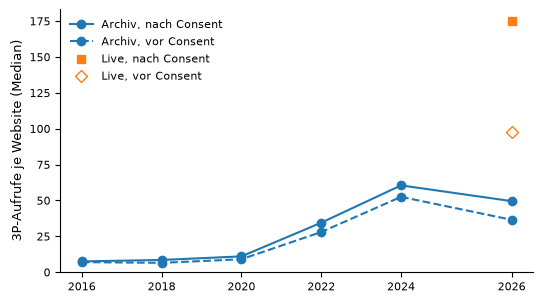

websites    summe  mittel  median  groesste  \
messung datum      punkt                                                
archiv  2016-01-01 nach        110   1756.0   15.96     7.5     211.0   
                   vor         110   1662.0   15.11     7.0     199.0   
        2018-01-01 nach        110   9094.0   82.67     8.5    5780.0   
                   vor         110   2771.0   25.19     6.5     677.0   
        2020-01-01 nach        110   5233.0   47.57    11.0    1689.0   
                   vor         110   3808.0   34.62     9.0    1343.0   
        2022-01-01 nach        110   6648.0   60.44    34.5     419.0   
                   vor         110   5804.0   52.76    28.0     419.0   
        2024-01-01 nach        110  10014.0   91.04    60.5     364.0   
                   vor         110   8574.0   77.95    52.5     326.0   
        2026-10-09 nach        110  12576.0  114.33    49.5    1519.0   
                   vor         110   9432.0   85.75    36.5     817.0   
live    2026-10-09 nach        109  63814.0  585.45   175.0   11581.0   
                   vor         109  23918.0  219.43    98.0    1848.0   

                          anteil_groesste  
messung datum      punkt                   
archiv  2016-01-01 nach              0.12  
                   vor               0.12  
        2018-01-01 nach              0.64  
                   vor               0.24  
        2020-01-01 nach              0.32  
                   vor               0.35  
        2022-01-01 nach              0.06  
                   vor               0.07  
        2024-01-01 nach              0.04  
                   vor               0.04  
        2026-10-09 nach              0.12  
                   vor               0.09  
live    2026-10-09 nach              0.18  
                   vor               0.08

In [10]:
# Zeitlinie: 3P-Aufrufe je Website über die Stichtage. Panel, nur Methoden, die zählen (ohne Storage und devicePixelRatio)
# Linie = Median je Website. Die Summe steht in der Tabelle, kann aber von einer einzelnen Website dominiert werden (anteil_groesste)
auswahl = calls[calls["website"].isin(panel_menge) & (calls["partei"] == "3P") & calls["zaehlt"]]
summen = auswahl.groupby(["messung", "stichtag", "punkt", "website"], as_index=False)["anzahl"].sum()
# Jede gemessene Panel-Website zählt, auch ohne Aufruf (dann 0)
basis = snap.loc[(snap["art"] == "gemessen") & snap["im_panel"], ["messung", "stichtag", "datum", "website"]]
basis = basis.merge(pd.DataFrame({"punkt": ["vor", "nach"]}), how="cross")
je_website = basis.merge(summen, on=["messung", "stichtag", "punkt", "website"], how="left").fillna({"anzahl": 0})

zeitlinie = je_website.groupby(["messung", "datum", "punkt"]).agg(
    websites=("website", "size"), summe=("anzahl", "sum"), mittel=("anzahl", "mean"),
    median=("anzahl", "median"), groesste=("anzahl", "max"))
zeitlinie["anteil_groesste"] = zeitlinie["groesste"] / zeitlinie["summe"]

fig, ax = plt.subplots(figsize=(BREITE, BREITE * 0.55), layout="constrained")
for punkt, stil in (("nach", "-"), ("vor", "--")):
    reihe = zeitlinie.loc[("archiv", slice(None), punkt), "median"].droplevel(["messung", "punkt"])
    ax.plot(reihe.index, reihe.values, stil, marker="o", color="C0", label=f"Archiv, {punkt} Consent")
for punkt, form in (("nach", "s"), ("vor", "D")):
    reihe = zeitlinie.loc[("live", slice(None), punkt), "median"].droplevel(["messung", "punkt"])
    ax.plot(reihe.index, reihe.values, form, color="C1", fillstyle="full" if punkt == "nach" else "none", label=f"Live, {punkt} Consent")
ax.set_ylabel("3P-Aufrufe je Website (Median)")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
jahresachse(ax)
speichern(fig, "zeitlinie")
plt.show()
zeitlinie.round(2)

**Zeitlinie**
- Median der 3P-Aufrufe je Website: bis 2020 kaum Änderung (7,5 → 11), dann Anstieg auf 60,5 (2024), 2026 bei 49,5
- Median statt Summe: 2018 stammen 64 % aller Aufrufe von einer einzigen Website
- Live am selben Tag 175, mehr als dreimal so viel wie im Archiv: das Archiv ist eine Untergrenze
- Nach Consent immer etwas mehr als vor Consent

Bis 2020 kaum Bewegung, dann ein starker Anstieg auf etwa das Achtfache bis 2024. 2026 liegt der Wert etwas darunter. Den Rückgang solltest du noch nicht deuten, er ist im Rahmen des Zufalls.
Darum Median statt Summe: 2018 stammen 64 % aller Aufrufe von einer einzigen Website. Die Summe würde dort einen Sprung zeigen, den es nicht gibt. Die Tabelle unter der Grafik zeigt das in der Spalte anteil_groesste.
Live liegt mehr als dreimal so hoch wie das Archiv am selben Tag (175 gegen 49,5). Das ist der Archivverlust: Die Zeitreihe ist eine Untergrenze.
Nach Consent liegt immer über vor Consent, live fast doppelt so hoch. Das ist schon ein Vorgriff auf FF3.
Weitere Auswertungen mit Stoff für 1–2 Seiten, nach Nutzen sortiert:

Verbreitung nach Wertung: Anteil der Websites mit mindestens einem starken Aufruf, etwa 1 % → 10 %. Das ist die Kernaussage zu H1. Statistik: Wilson-Intervall und McNemar 2016 gegen 2024.
Je Technik einzeln: Canvas, WebGL, Audio, Browser, Bildschirm, Gerät als Anteil der Websites, als Heatmap oder kleine Einzelgrafiken. Das bringt den meisten Stoff:
Client Hints ersetzen den User-Agent-String (Chrome hat den String eingefroren).
plugins verschwindet (Ende von Flash).
Zeitzone und Sprachliste nehmen zu.
Breite: Anzahl verschiedener Methoden je Website, etwa 3 → 6. Dazu ein Kombi-Indikator: Canvas, WebGL und Audio zusammen sind das typische Muster echten Fingerprintings. Statistik: Friedman, Wilcoxon.
Anbieter: Welche Quellen die Aufrufe auslösen, Top 10 je Stichtag, Anteil der größten. Daraus lässt sich ableiten, ob wenige Konzerne (z. B. Google-Tags) den Trend treiben.
1P gegen 3P: Wandert Fingerprinting in die Website selbst, etwa über eigene Skripte oder Tag-Manager? Die Daten dafür liegen schon in calls.
Rangbereiche: Top-1000 gegen Long Tail, nur beschreibend.
Brückenpunkt je Technik: Was das Archiv verliert, ist Stoff für die Diskussion der Grenzen.


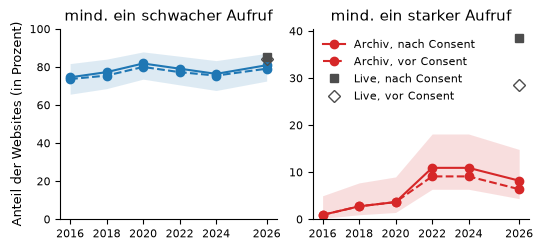

websites  stark  schwach  anteil_stark  \
messung datum      punkt                                           
archiv  2016-01-01 nach        110      1       82           0.9   
                   vor         110      1       81           0.9   
        2018-01-01 nach        110      3       85           2.7   
                   vor         110      3       83           2.7   
        2020-01-01 nach        110      4       90           3.6   
                   vor         110      4       88           3.6   
        2022-01-01 nach        110     12       87          10.9   
                   vor         110     10       85           9.1   
        2024-01-01 nach        110     12       84          10.9   
                   vor         110     10       83           9.1   
        2026-10-09 nach        110      9       89           8.2   
                   vor         110      7       87           6.4   
live    2026-10-09 nach        109     42       93          38.5   
                   vor         109     31       92          28.4   

                          anteil_schwach  
messung datum      punkt                  
archiv  2016-01-01 nach             74.5  
                   vor              73.6  
        2018-01-01 nach             77.3  
                   vor              75.5  
        2020-01-01 nach             81.8  
                   vor              80.0  
        2022-01-01 nach             79.1  
                   vor              77.3  
        2024-01-01 nach             76.4  
                   vor              75.5  
        2026-10-09 nach             80.9  
                   vor              79.1  
live    2026-10-09 nach             85.3  
                   vor              84.4

In [11]:
# Verbreitung: Anteil der Panel-Websites mit mind. einem schwachen bzw. starken 3P-Aufruf je Stichtag
# Band = 95-%-Konfidenzintervall nach Wilson (bei kleinen Anteilen genauer als das einfache Intervall)
from statsmodels.stats.proportion import proportion_confint

je_wertung = (auswahl.assign(stark=auswahl["wertung"] == "stark", schwach=auswahl["wertung"] == "schwach")
              .groupby(["messung", "stichtag", "punkt", "website"], as_index=False)[["stark", "schwach"]].any())
verbreitung = (basis.merge(je_wertung, on=["messung", "stichtag", "punkt", "website"], how="left")
               .fillna({"stark": False, "schwach": False}).astype({"stark": bool, "schwach": bool}))
anteile = verbreitung.groupby(["messung", "datum", "punkt"]).agg(websites=("website", "size"), stark=("stark", "sum"), schwach=("schwach", "sum"))

fig, achsen = plt.subplots(1, 2, figsize=(BREITE, BREITE * 0.45), layout="constrained")
for ax, wertung, farbe in zip(achsen, ("schwach", "stark"), ("C0", "C3")):
    for punkt, stil in (("nach", "-"), ("vor", "--")):
        reihe = anteile.xs(("archiv", punkt), level=("messung", "punkt"))
        ax.plot(reihe.index, reihe[wertung] / reihe["websites"] * 100, stil, marker="o", color=farbe, label=f"Archiv, {punkt} Consent")
        if punkt == "nach":
            unten, oben = proportion_confint(reihe[wertung], reihe["websites"], method="wilson")
            ax.fill_between(reihe.index, unten * 100, oben * 100, color=farbe, alpha=0.15, linewidth=0)
    for punkt, form in (("nach", "s"), ("vor", "D")):
        reihe = anteile.xs(("live", punkt), level=("messung", "punkt"))
        ax.plot(reihe.index, reihe[wertung] / reihe["websites"] * 100, form, color="0.3",
                fillstyle="full" if punkt == "nach" else "none", label=f"Live, {punkt} Consent")
    ax.set_title(f"mind. ein {wertung}er Aufruf")
    ax.set_ylim(bottom=0)
    jahresachse(ax)
achsen[0].set_ylim(top=100)
achsen[0].set_ylabel("Anteil der Websites (in Prozent)")
achsen[1].legend(frameon=False, loc="upper left")
speichern(fig, "verbreitung")
plt.show()
anteile.assign(anteil_stark=anteile["stark"] / anteile["websites"] * 100, anteil_schwach=anteile["schwach"] / anteile["websites"] * 100).round(1)

**Verbreitung**
- Mind. ein schwacher Aufruf: an allen Stichtagen 74–82 % der Websites, kaum Veränderung
- Mind. ein starker Aufruf: 0,9 % (2016) → 10,9 % (2022 und 2024) → 8,2 % (2026)
- Der Rückgang 2024 → 2026 liegt im Konfidenzband und ist nicht belastbar
- Live nach Consent 38,5 % mit starkem Aufruf, im Archiv 8,2 %: starke Techniken gehen im Archiv besonders verloren

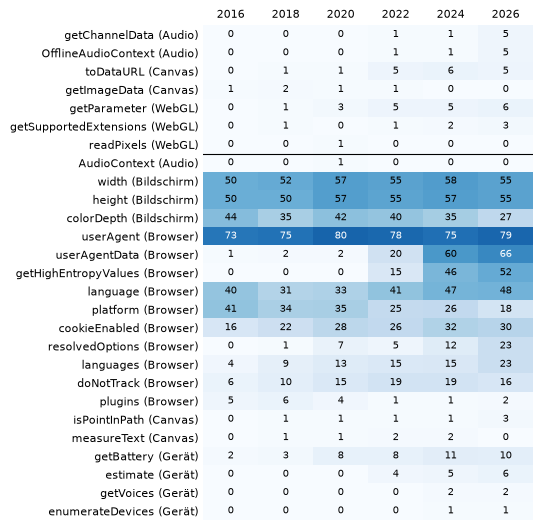

In [12]:
# Technikwandel: Anteil der Panel-Websites mit mind. einem 3P-Aufruf je Methode und Stichtag (Archiv, nach Consent)
archiv_nach = auswahl[(auswahl["messung"] == "archiv") & (auswahl["punkt"] == "nach")]
heat = (archiv_nach.groupby(["methode", "stichtag"])["website"].nunique().unstack(fill_value=0)
        .reindex(columns=STICHTAGE, fill_value=0) / len(panel) * 100)
# Reihenfolge: stark oben, dann nach Kategorie, innerhalb nach dem höchsten Anteil
info = METHODEN.set_index("methode").loc[heat.index]
info = info.assign(hoechster=heat.max(axis=1)).sort_values(["wertung", "kategorie", "hoechster"], ascending=[False, True, False])
heat = heat.loc[info.index]

fig, ax = plt.subplots(figsize=(BREITE, 0.17 * len(heat) + 0.6), layout="constrained")
ax.pcolormesh(heat.values, cmap="Blues", vmin=0, vmax=100) # pcolormesh bleibt Vektor, imshow wäre ein Pixelbild
for zeile, werte in enumerate(heat.values):
    for spalte, wert in enumerate(werte):
        ax.text(spalte + 0.5, zeile + 0.5, f"{wert:.0f}", ha="center", va="center", fontsize=7, color="white" if wert > 60 else "black")
ax.set_xticks([i + 0.5 for i in range(len(STICHTAGE))], [tag[:4] for tag in STICHTAGE])
ax.set_yticks([i + 0.5 for i in range(len(heat))], [f"{m.rpartition('.')[2]} ({info.loc[m, 'kategorie']})" for m in heat.index])
ax.invert_yaxis()
ax.xaxis.tick_top()
ax.tick_params(length=0)
for seite in ax.spines.values():
    seite.set_visible(False)
# Trennlinie zwischen starken (oben) und schwachen Methoden
ax.axhline((info["wertung"] == "stark").sum(), color="black", linewidth=0.8)
speichern(fig, "techniken")
plt.show()

**Techniken**
- Größte Verschiebung bei den schwachen Merkmalen: Client Hints ab 2022 (userAgentData 1 % → 66 %, getHighEntropyValues 0 % → 52 %)
- Rückläufig: platform (41 % → 18 %), colorDepth (44 % → 27 %), plugins (5 % → 2 %)
- Neu dazu: Zeitzone (resolvedOptions 0 % → 23 %) und Sprachliste (languages 4 % → 23 %)
- Starke Methoden bleiben selten (höchstens 6 % je Methode), Audio erst ab 2022

In [13]:
# Anbieter: Top 10 der Quellen (eTLD+1) nach Anzahl der Panel-Websites mit 3P-Aufruf (Archiv, nach Consent)
# stark_2026: Quelle macht am letzten Stichtag mind. einen starken Aufruf
quellen = (archiv_nach.groupby(["quelle", "stichtag"])["website"].nunique().unstack(fill_value=0)
           .reindex(columns=STICHTAGE, fill_value=0))
quellen.columns = [tag[:4] for tag in STICHTAGE]
stark_2026 = set(archiv_nach.loc[(archiv_nach["stichtag"] == STICHTAGE[-1]) & (archiv_nach["wertung"] == "stark"), "quelle"])
top = quellen.sort_values("2026", ascending=False).head(10)
top.assign(stark_2026=top.index.isin(stark_2026))

,2016,2018,2020,2022,2024,2026,stark_2026
quelle,,,,,,,
googletagmanager.com,13,17,22,47,59,47,False
facebook.net,8,16,28,23,19,14,False
gstatic.com,6,8,10,10,9,12,False
cloudflareinsights.com,0,0,0,4,6,9,False
google.com,16,16,11,8,7,9,False
clarity.ms,0,0,0,2,6,7,False
doubleclick.net,5,3,8,7,8,6,False
yandex.ru,8,7,5,4,6,6,False
go-mpulse.net,1,0,0,2,5,5,False


**Anbieter**
- googletagmanager.com ist mit Abstand die häufigste Quelle: 13 (2016) → 59 (2024) → 47 (2026) Websites
- facebook.net steigt bis 2020 (28) und fällt danach (14), google.com fällt von 16 auf 9
- Neu ab 2022: cloudflareinsights.com, clarity.ms, go-mpulse.net
- Von den Top 10 macht 2026 nur youtube.com starke Aufrufe: starke Aufrufe kommen von seltenen Quellen

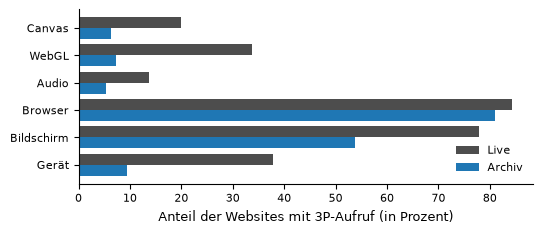

95 Websites am Brückenpunkt


messung,live,archiv
kategorie,,
Canvas,20.0,6.3
WebGL,33.7,7.4
Audio,13.7,5.3
Browser,84.2,81.1
Bildschirm,77.9,53.7
Gerät,37.9,9.5


In [14]:
# Brückenpunkt: Anteil der Websites mit mind. einem 3P-Aufruf je Kategorie, live vs. Archiv am letzten Stichtag (nach Consent)
# Nur Panel-Websites mit Live-Messung und Snapshot höchstens 30 Tage vor dem Live-Crawl, damit beide dieselbe Website zeigen
nah = snap.loc[(snap["messung"] == "archiv") & (snap["stichtag"] == STICHTAGE[-1]) & snap["im_panel"] & (snap["abstand_tage"] >= -30), "website"]
live_ok = snap.loc[(snap["messung"] == "live") & (snap["art"] == "gemessen"), "website"]
bruecke = sorted(set(nah) & set(live_ok))
teil = auswahl[auswahl["website"].isin(bruecke) & (auswahl["punkt"] == "nach") & auswahl["stichtag"].isin([STICHTAGE[-1], "live"])]
kategorien = ["Canvas", "WebGL", "Audio", "Browser", "Bildschirm", "Gerät"]
vergleich = (teil.groupby(["kategorie", "messung"])["website"].nunique().unstack(fill_value=0)
             .reindex(index=kategorien, columns=["live", "archiv"], fill_value=0) / len(bruecke) * 100)

fig, ax = plt.subplots(figsize=(BREITE, BREITE * 0.42), layout="constrained")
for versatz, messung, farbe, name in ((-0.2, "live", "0.3", "Live"), (0.2, "archiv", "C0", "Archiv")):
    ax.barh([i + versatz for i in range(len(kategorien))], vergleich[messung], height=0.4, color=farbe, label=name)
ax.set_yticks(range(len(kategorien)), kategorien)
ax.invert_yaxis()
ax.set_xlabel("Anteil der Websites mit 3P-Aufruf (in Prozent)")
ax.legend(frameon=False, loc="lower right")
speichern(fig, "brueckenpunkt")
plt.show()
print(len(bruecke), "Websites am Brückenpunkt")
vergleich.round(1)

**Brückenpunkt**
- 95 Panel-Websites mit Live-Messung und Snapshot höchstens 30 Tage vor dem Live-Crawl
- Browser-Merkmale fast gleich (84 % live, 81 % Archiv), Bildschirm 78 % zu 54 %
- Starke Techniken und Gerät fehlen im Archiv stark: Canvas 20 % zu 6 %, WebGL 34 % zu 7 %, Audio 14 % zu 5 %, Gerät 38 % zu 10 %
- Die Zeitreihe ist deshalb vor allem bei starken Techniken eine Untergrenze

## Statistik

**Anzeigen**
- Verbreitung: Anteil Websites mit mind. einem starken 3P-Aufruf je Stichtag mit 95-%-KI, nach Consent durchgezogen, vor gestrichelt, Live-Punkt daneben
- Intensität: Median der schwachen 3P-Aufrufe je Website, log-Achse, Band für die mittleren 50 %
- Technikwandel: Heatmap Methode × Stichtag (Anteil Websites), Zeilen nach Wertung sortiert
- Umverteilung als eine Zahl: Spearman der Methoden-Rangfolge gegen 2016
- Anbieter: Top-Quellen je Stichtag
- Brückenpunkt: live vs. Archiv je Methode (Hantel-Diagramm)
- Trichter als Tabelle: 500 → 351 → 201 → 110

**Statistik**
- Anteile: Wilson-Konfidenzintervall
- Änderung ja/nein im Panel: Cochran-Q über alle Stichtage, exakter McNemar paarweise (2016 vs. 2024 und 2026), Holm-Korrektur
- Aufrufzahlen im Panel: Friedman, paarweise Wilcoxon mit Effektstärke r
- Rangfolge der Methoden zwischen Jahren: Spearman
- Live vs. Archiv: Spearman der Aufrufe, Cohen's κ für ja/nein, Jaccard der Quellen
- Nicht: Pearson auf Rohzahlen (Ausreißer), χ²-Tests über Stichtage (dieselben Websites)

In [15]:
# Anteil mit starkem Aufruf: Ändert er sich? Dieselben 110 Websites an allen Stichtagen, deshalb gepaarte Tests (Archiv, nach Consent)
# Cochran-Q: gibt es über alle 6 Stichtage irgendeinen Unterschied. McNemar exakt: zwei Stichtage paarweise, Holm-Korrektur für mehrere Tests
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests

stark_tabelle = (verbreitung[(verbreitung["messung"] == "archiv") & (verbreitung["punkt"] == "nach")]
                 .pivot(index="website", columns="stichtag", values="stark")[STICHTAGE])
q = cochrans_q(stark_tabelle.astype(int))
print(f"Cochran-Q = {q.statistic:.1f}, p = {q.pvalue:.4f}")

PAARE = [(STICHTAGE[0], STICHTAGE[4]), (STICHTAGE[0], STICHTAGE[5]), (STICHTAGE[4], STICHTAGE[5])] # 2016-2024, 2016-2026, 2024-2026
zeilen_mcnemar = []
for a, b in PAARE:
    # Vierfeldertafel: Zeilen = vorher stark ja/nein, Spalten = nachher stark ja/nein
    tafel = pd.crosstab(stark_tabelle[a], stark_tabelle[b]).reindex(index=[False, True], columns=[False, True], fill_value=0)
    zeilen_mcnemar.append({"vergleich": f"{a[:4]} -> {b[:4]}", "neu_stark": tafel.loc[False, True],
                           "nicht_mehr_stark": tafel.loc[True, False], "p": mcnemar(tafel, exact=True).pvalue})
test_stark = pd.DataFrame(zeilen_mcnemar)
test_stark["p_holm"] = multipletests(test_stark["p"], method="holm")[1]
test_stark.round(4)

Cochran-Q = 22.2, p = 0.0005


,vergleich,neu_stark,nicht_mehr_stark,p,p_holm
0,2016 -> 2024,12,1,0.0034,0.0103
1,2016 -> 2026,9,1,0.0215,0.0430
2,2024 -> 2026,4,7,0.5488,0.5488


**Test: Anteil mit starkem Aufruf**
- Cochran-Q p = 0,0005: über die 6 Stichtage ändert sich der Anteil deutlich
- 2016 → 2024: 12 Websites neu mit starkem Aufruf, 1 nicht mehr (p = 0,01 nach Holm), signifikanter Anstieg
- 2016 → 2026: 9 neu, 1 nicht mehr (p = 0,04), ebenfalls signifikant
- 2024 → 2026: 4 neu, 7 nicht mehr (p = 0,55), kein belastbarer Unterschied

In [16]:
# Aufrufe je Website: Ändern sie sich? Friedman über alle Stichtage, Wilcoxon paarweise (Archiv, nach Consent)
# Beides sind Rangtests: unempfindlich gegen Ausreißer. Effektstärke r = |z| / Wurzel(n), grob: 0,1 klein, 0,3 mittel, 0,5 groß
from scipy.stats import friedmanchisquare, wilcoxon

aufrufe_tabelle = (je_website[(je_website["messung"] == "archiv") & (je_website["punkt"] == "nach")]
                   .pivot(index="website", columns="stichtag", values="anzahl")[STICHTAGE])
f = friedmanchisquare(*[aufrufe_tabelle[tag] for tag in STICHTAGE])
print(f"Friedman = {f.statistic:.1f}, p = {f.pvalue:.4g}")

zeilen_wilcoxon = []
for a, b in PAARE:
    w = wilcoxon(aufrufe_tabelle[a], aufrufe_tabelle[b], method="approx")
    zeilen_wilcoxon.append({"vergleich": f"{a[:4]} -> {b[:4]}", "median_vorher": aufrufe_tabelle[a].median(),
                            "median_nachher": aufrufe_tabelle[b].median(), "p": w.pvalue,
                            "r": abs(w.zstatistic) / len(aufrufe_tabelle) ** 0.5})
test_aufrufe = pd.DataFrame(zeilen_wilcoxon)
test_aufrufe["p_holm"] = multipletests(test_aufrufe["p"], method="holm")[1]
test_aufrufe.round(4)

Friedman = 91.7, p = 2.942e-18


,vergleich,median_vorher,median_nachher,p,r,p_holm
0,2016 -> 2024,7.5,60.5,0.0000,0.6560,0.0000
1,2016 -> 2026,7.5,49.5,0.0000,0.6316,0.0000
2,2024 -> 2026,60.5,49.5,0.4998,0.0643,0.4998


**Test: Aufrufe je Website**
- Friedman p < 0,001: die Aufrufe je Website ändern sich über die Stichtage deutlich
- 2016 → 2024: Median 7,5 → 60,5, r = 0,66 (großer Effekt), 2016 → 2026: 7,5 → 49,5, r = 0,63
- 2024 → 2026: 60,5 → 49,5, p = 0,50, r = 0,06, kein belastbarer Unterschied

In [17]:
# Umverteilung der Techniken: Spearman-Korrelation der Methoden-Rangfolge zwischen den Stichtagen (aus der Heatmap)
# 1 = gleiche Reihenfolge der Methoden, je kleiner, desto stärker hat sich verschoben, welche Methoden häufig sind
rangfolge = heat.corr(method="spearman")
rangfolge.index = rangfolge.columns = [tag[:4] for tag in STICHTAGE]
rangfolge.round(2)

,2016,2018,2020,2022,2024,2026
2016,1.00,0.94,0.90,0.80,0.68,0.65
2018,0.94,1.00,0.93,0.83,0.70,0.64
2020,0.90,0.93,1.00,0.81,0.68,0.65
2022,0.80,0.83,0.81,1.00,0.94,0.91
2024,0.68,0.70,0.68,0.94,1.00,0.95
2026,0.65,0.64,0.65,0.91,0.95,1.00


**Umverteilung der Techniken**
- 2016 bis 2020 ähnliche Reihenfolge der Methoden (Spearman mind. 0,90), ebenso 2022 bis 2026 (mind. 0,91)
- Zwischen den beiden Blöcken nur 0,64 bis 0,83: der Wechsel der Techniken passiert zwischen 2020 und 2022 (Client Hints)

In [18]:
# Brückenpunkt: Wie gut gibt das Archiv die Live-Messung wieder? Gleiche Websites wie in der Abbildung (nach Consent)
# Spearman: gleiche Reihenfolge der Websites nach Aufrufen. Kappa: Übereinstimmung bei stark ja/nein über den Zufall hinaus (0 = Zufall, 1 = perfekt)
from statsmodels.stats.inter_rater import cohens_kappa

am_brueckenpunkt = lambda tabelle: tabelle[tabelle["website"].isin(bruecke) & (tabelle["punkt"] == "nach") & tabelle["stichtag"].isin([STICHTAGE[-1], "live"])]
aufrufe_paar = am_brueckenpunkt(je_website).pivot(index="website", columns="messung", values="anzahl")
stark_paar = am_brueckenpunkt(verbreitung).pivot(index="website", columns="messung", values="stark")

# Wiederfindung: Anteil der live gefundenen (Website, Quelle)-Paare, die auch im Archiv vorkommen
quellen = teil[["website", "messung", "quelle"]].drop_duplicates()
live_quellen = quellen[quellen["messung"] == "live"]
archiv_quellen = quellen[quellen["messung"] == "archiv"]
wiederfindung = len(live_quellen.merge(archiv_quellen, on=["website", "quelle"])) / len(live_quellen)

print(f"{len(bruecke)} Websites am Brückenpunkt")
print(f"Spearman Aufrufe live/Archiv: {aufrufe_paar['live'].corr(aufrufe_paar['archiv'], method='spearman'):.2f}")
print(f"Kappa stark ja/nein: {cohens_kappa(pd.crosstab(stark_paar['live'], stark_paar['archiv'])).kappa:.2f}")
print(f"Live gefundene Quellen auch im Archiv: {wiederfindung:.0%}")

95 Websites am Brückenpunkt
Spearman Aufrufe live/Archiv: 0.63
Kappa stark ja/nein: 0.28
Live gefundene Quellen auch im Archiv: 38%


**Test: Brückenpunkt**
- Spearman 0,63: Websites mit vielen Aufrufen live haben meist auch im Archiv viele, die Reihenfolge bleibt grob erhalten
- Kappa 0,28: bei stark ja/nein nur schwache Übereinstimmung, das Archiv übersieht viele starke Aufrufe
- Nur 38 % der live gefundenen Quellen tauchen im Archiv auf
- Fazit: das Archiv taugt für Trends, die absoluten Werte sind eine Untergrenze

# Nebenfakten

- Auswahl des Panels: Verteilung auf die Rangbereiche
- Robustheit: Ergebnisse zusätzlich mit allen gültigen Snapshots statt nur dem Panel (folgt, sobald die Kennzahlen stehen)

In [19]:
# Auswahl des Panels prüfen: Im Panel stehen nur Websites, die seit 2016 archiviert sind. 
# Rang aus der Tranco-Liste, Grenzen der Rangbereiche aus der Konfiguration (wie beim Ziehen der Stichprobe, utils/tranco_worker.py)
import csv
from itertools import islice

GRENZEN = configs["hist"][-1]["rank_bands"]
with open(configs["hist"][-1]["path_to_webpages"], encoding="utf-8") as datei:
    rang = {domain: int(platz) for platz, domain in islice(csv.reader(datei), GRENZEN[-1])}

def rangbereich(website):
    platz = rang[website.removeprefix("https://")]
    return next(bereich for bereich, grenze in enumerate(GRENZEN, 1) if platz <= grenze)

for name, liste in {"Stichprobe": websites, "vollständig": vollstaendig, "Panel": panel}.items():
    zaehler = Counter(rangbereich(website) for website in liste)
    print(f"{name:12s} n={len(liste):3d}  je Rangbereich:", {bereich: zaehler[bereich] for bereich in range(1, len(GRENZEN) + 1)})

Stichprobe   n=500  je Rangbereich: {1: 125, 2: 125, 3: 125, 4: 125}
vollständig  n=201  je Rangbereich: {1: 66, 2: 54, 3: 44, 4: 37}
Panel        n=110  je Rangbereich: {1: 35, 2: 25, 3: 25, 4: 25}


In [20]:
from statsmodels.stats.contingency_tables import cochrans_q

print("== 1. Konfiguration der Laeufe (Consent im Archiv? Stichprobengroesse?)")
for name in ("hist", "live"):
    for config in configs[name]:
        print(name, {key: config.get(key) for key in ("consent", "batch_size", "max_days_gap", "loading_time",
                                                      "visit_time_after_consent", "wayback_max_wait", "target_dates")})

print("\n== 2. Consent-Klick erfolgreich (Anteil der Panel-Messungen)")
klick = snap[(snap["art"] == "gemessen") & snap["im_panel"]]
print(klick.groupby("stichtag")["consent_klick"].apply(lambda werte: werte.astype("boolean").mean()).round(2))

print("\n== 3. Abstand Snapshot zu Stichtag im Panel (Tage) und Wartezeit an der Hoechstgrenze")
archiv = snap[(snap["messung"] == "archiv") & snap["im_panel"] & (snap["art"] == "gemessen")]
print(archiv.groupby("stichtag").agg(median_abstand=("abstand_tage", lambda tage: tage.abs().median()),
                                     max_abstand=("abstand_tage", lambda tage: tage.abs().max()),
                                     nach_stichtag=("abstand_tage", lambda tage: (tage > 0).sum()),
                                     wartezeit_gekappt=("wartezeit_gekappt", "mean")).round(2))

print("\n== 4. Zeitmix: Anteil der gezaehlten 3P-Aufrufe aus Skript-Kopien mit mehr als 365 Tagen Abstand (Archiv, Messpunkt 2)")
a = auswahl[(auswahl["messung"] == "archiv") & (auswahl["punkt"] == "nach")]
zeitmix = a.assign(zeitmix_anzahl=a["anzahl"].where(a["zeitmix"], 0)).groupby("stichtag")[["zeitmix_anzahl", "anzahl"]].sum()
zeitmix["anteil"] = (zeitmix["zeitmix_anzahl"] / zeitmix["anzahl"]).round(3)
zeitmix["websites_mit_zeitmix"] = a[a["zeitmix"]].groupby("stichtag")["website"].nunique()
zeitmix["websites_stark_nur_zeitmix"] = (a[a["wertung"] == "stark"].groupby(["stichtag", "website"])["zeitmix"].all()
                                         .groupby("stichtag").sum())
print(zeitmix.fillna(0))

print("\n== 5. Client Hints vor 2022 (gab es im Original noch nicht): woher kommen sie?")
frueh = a[a["methode"].isin(["Navigator.userAgentData", "NavigatorUAData.getHighEntropyValues"]) & a["stichtag"].isin(STICHTAGE[:3])]
for zeile in frueh.itertuples():
    luecke = (letzte["hist"][(zeile.website, zeile.stichtag)]["stats_nach_consent"].get("script_gap_days") or {}).get(zeile.quelle)
    print(zeile.stichtag, zeile.website, zeile.methode, zeile.quelle, "Abstand Skript-Kopie:", luecke, "Tage")

print("\n== 6. Robustheit: alle fehlerfreien Snapshots je Stichtag statt nur Panel (Messpunkt 2)")
alle = snap[(snap["messung"] == "archiv") & (snap["art"] == "gemessen")][["stichtag", "website"]]
alle = alle[[not probleme(website, stichtag) for website, stichtag in zip(alle["website"], alle["stichtag"])]]
c = calls[(calls["messung"] == "archiv") & (calls["partei"] == "3P") & calls["zaehlt"] & (calls["punkt"] == "nach")]
summe = c.groupby(["stichtag", "website"])["anzahl"].sum()
stark = c[c["wertung"] == "stark"].groupby(["stichtag", "website"]).size() > 0
robust = alle.set_index(["stichtag", "website"])
robust["anzahl"] = summe.reindex(robust.index).fillna(0).to_numpy()
robust["stark"] = stark.reindex(robust.index).fillna(False).astype(bool).to_numpy()
print(robust.groupby(level="stichtag").agg(websites=("anzahl", "size"), median=("anzahl", "median"),
                                           anteil_stark_prozent=("stark", lambda s: round(s.mean() * 100, 1))))

print("\n== 7. Schwache Merkmale: Test ueber die Stichtage und Anteil ohne userAgent (Panel, Archiv, Messpunkt 2)")
schwach_tabelle = (verbreitung[(verbreitung["messung"] == "archiv") & (verbreitung["punkt"] == "nach")]
                   .pivot(index="website", columns="stichtag", values="schwach")[STICHTAGE])
q_schwach = cochrans_q(schwach_tabelle.astype(int))
print(f"Cochran-Q schwach = {q_schwach.statistic:.1f}, p = {q_schwach.pvalue:.4f}")
ohne_ua = a[(a["wertung"] == "schwach") & (a["methode"] != "Navigator.userAgent")].groupby("stichtag")["website"].nunique()
print("Anteil mit schwachem Aufruf ausser userAgent (Prozent):", (ohne_ua.reindex(STICHTAGE, fill_value=0) / len(panel) * 100).round(1).to_dict())

print("\n== 8. Anteil von googletagmanager.com an den gezaehlten 3P-Aufrufen (Panel, Archiv, Messpunkt 2)")
gtm = a.assign(gtm=a["anzahl"].where(a["quelle"] == "googletagmanager.com", 0)).groupby("stichtag")[["gtm", "anzahl"]].sum()
print((gtm["gtm"] / gtm["anzahl"]).round(3).to_dict())

print("\n== 9. Brueckenpunkt: wie viel der Live-Aufrufe das Archiv erfasst (gleiche 95 Websites, Messpunkt 2)")
paar = aufrufe_paar[aufrufe_paar["live"] > 0]
print("Archiv/Live je Website, Median:", round((paar["archiv"] / paar["live"]).median(), 2))
print("Archiv/Live ueber alle Aufrufe:", round(aufrufe_paar["archiv"].sum() / aufrufe_paar["live"].sum(), 2))
print("Websites live ohne Aufruf:", int((aufrufe_paar["live"] == 0).sum()), "| Archiv hoeher als live:", int((aufrufe_paar["archiv"] > aufrufe_paar["live"]).sum()))
import numpy as np
print("Pearson auf log(1 + Aufrufe):", round(np.log1p(aufrufe_paar["live"]).corr(np.log1p(aufrufe_paar["archiv"])), 2))

print("\n== 10. Aufrufe ohne 1P/3P-Zuordnung (partei unbekannt)")
print(calls.groupby(["messung", "partei"])["anzahl"].sum().unstack(fill_value=0))


== 1. Konfiguration der Laeufe (Consent im Archiv? Stichprobengroesse?)
hist {'consent': True, 'batch_size': 500, 'max_days_gap': 120, 'loading_time': 10, 'visit_time_after_consent': 10, 'wayback_max_wait': 45, 'target_dates': ['20160101', '20180101', '20200101', '20220101', '20240101', '20261009']}
hist {'consent': True, 'batch_size': 500, 'max_days_gap': 120, 'loading_time': 10, 'visit_time_after_consent': 10, 'wayback_max_wait': 45, 'target_dates': ['20160101', '20180101', '20200101', '20220101', '20240101', '20261009']}
hist {'consent': True, 'batch_size': 500, 'max_days_gap': 120, 'loading_time': 10, 'visit_time_after_consent': 10, 'wayback_max_wait': 45, 'target_dates': ['20160101', '20180101', '20200101', '20220101', '20240101', '20261009']}
live {'consent': True, 'batch_size': 500, 'max_days_gap': 60, 'loading_time': 10, 'visit_time_after_consent': 10, 'wayback_max_wait': 45, 'target_dates': ['20160101', '20200101', '20240101', '20261005']}
live {'consent': True, 'batch_size': 

In [21]:
# FF1-Kennzahlen fuer einen waehlbaren Messpunkt (Quartile, Median ohne Zeitmix bzw. ohne googletagmanager.com,
# Test ohne userAgent, Quartile der Erfassungsquote, Live-Lecks). PUNKT = "nach" wie in der Live-Messung,
# PUNKT = "vor" als Gegenprobe fuer Messpunkt 1. Nutzt nur Variablen des Notebooks, speichert nichts.
PUNKT = "nach"  # "nach" = Messpunkt 2, "vor" = Messpunkt 1

import numpy as np
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.inter_rater import cohens_kappa
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import friedmanchisquare, wilcoxon

a = auswahl[(auswahl["messung"] == "archiv") & (auswahl["punkt"] == PUNKT)]
v = verbreitung[(verbreitung["messung"] == "archiv") & (verbreitung["punkt"] == PUNKT)]
j = je_website[(je_website["messung"] == "archiv") & (je_website["punkt"] == PUNKT)]
n_panel = len(panel)


def mcnemar_paare(tabelle, werte=(False, True)):
    # Exakter McNemar fuer die Paare 2016-2024, 2016-2026, 2024-2026, Holm-Korrektur
    zeilen = []
    for vorher, nachher in PAARE:
        tafel = pd.crosstab(tabelle[vorher], tabelle[nachher]).reindex(index=list(werte), columns=list(werte), fill_value=0)
        zeilen.append({"vergleich": f"{vorher[:4]} -> {nachher[:4]}", "neu": tafel.loc[werte[0], werte[1]],
                       "weg": tafel.loc[werte[1], werte[0]], "p": mcnemar(tafel, exact=True).pvalue})
    ergebnis = pd.DataFrame(zeilen)
    ergebnis["p_holm"] = multipletests(ergebnis["p"], method="holm")[1]
    return ergebnis.round(4).to_string(index=False)


print(f"===== Messpunkt: {PUNKT}, Panel n = {n_panel}")

print("\n== 1. Verbreitung: Websites mit starkem und schwachem Aufruf (Anzahl, Prozent, Wilson-95-%-Intervall fuer stark)")
anteil = v.groupby("stichtag")[["stark", "schwach"]].sum().reindex(STICHTAGE)
unten, oben = proportion_confint(anteil["stark"], n_panel, method="wilson")
anteil = anteil.assign(stark_prozent=anteil["stark"] / n_panel * 100, ki_unten=unten * 100, ki_oben=oben * 100,
                       schwach_prozent=anteil["schwach"] / n_panel * 100)
print(anteil.round(1).to_string())
live_v = verbreitung[(verbreitung["messung"] == "live") & (verbreitung["punkt"] == PUNKT)]
print(f"live: n = {len(live_v)}, stark {live_v['stark'].sum()} ({live_v['stark'].mean() * 100:.1f} %), schwach {live_v['schwach'].sum()} ({live_v['schwach'].mean() * 100:.1f} %)")

stark_tab = v.pivot(index="website", columns="stichtag", values="stark")[STICHTAGE]
q = cochrans_q(stark_tab.astype(int))
print(f"\nstark: Cochran-Q = {q.statistic:.1f}, p = {q.pvalue:.4f}")
print(mcnemar_paare(stark_tab))
schwach_tab = v.pivot(index="website", columns="stichtag", values="schwach")[STICHTAGE]
q = cochrans_q(schwach_tab.astype(int))
print(f"schwach: Cochran-Q = {q.statistic:.1f}, p = {q.pvalue:.4f}")
ohne_ua = a[(a["wertung"] == "schwach") & (a["methode"] != "Navigator.userAgent")][["stichtag", "website"]].drop_duplicates().assign(ja=1)
ua_tab = (basis[(basis["messung"] == "archiv") & (basis["punkt"] == PUNKT)][["stichtag", "website"]]
          .merge(ohne_ua, on=["stichtag", "website"], how="left").fillna({"ja": 0})
          .pivot(index="website", columns="stichtag", values="ja")[STICHTAGE].astype(int))
q = cochrans_q(ua_tab)
print(f"schwach ohne userAgent (Prozent): {(ua_tab.mean() * 100).round(1).to_dict()}")
print(f"schwach ohne userAgent: Cochran-Q = {q.statistic:.1f}, p = {q.pvalue:.4f}")
print(mcnemar_paare(ua_tab, werte=(0, 1)))

print("\n== 2. Intensitaet: 3P-Aufrufe je Website (Median, Quartile), Friedman, Wilcoxon")
tab = j.pivot(index="website", columns="stichtag", values="anzahl")[STICHTAGE]
print(tab.describe(percentiles=[0.25, 0.5, 0.75]).loc[["count", "25%", "50%", "75%", "max"]].round(1).to_string())
live_j = je_website[(je_website["messung"] == "live") & (je_website["punkt"] == PUNKT)]["anzahl"]
print(f"live: n = {len(live_j)}, Median = {live_j.median()}, Quartile = {live_j.quantile(0.25)} / {live_j.quantile(0.75)}")
summe = tab.sum()
print("Anteil der groessten Website an der Summe:", (tab.max() / summe).round(2).to_dict())
f = friedmanchisquare(*[tab[tag] for tag in STICHTAGE])
print(f"Friedman = {f.statistic:.1f}, p = {f.pvalue:.3g}")
zeilen = []
for vorher, nachher in PAARE:
    w = wilcoxon(tab[vorher], tab[nachher], method="approx")
    paare = int((tab[vorher] != tab[nachher]).sum())
    zeilen.append({"vergleich": f"{vorher[:4]} -> {nachher[:4]}", "median_vorher": tab[vorher].median(), "median_nachher": tab[nachher].median(),
                   "p": w.pvalue, "r_alle": abs(w.zstatistic) / len(tab) ** 0.5, "r_paare": abs(w.zstatistic) / paare ** 0.5, "paare": paare})
wx = pd.DataFrame(zeilen)
wx["p_holm"] = multipletests(wx["p"], method="holm")[1]
print(wx.round(4).to_string(index=False))


def median_mit(maske):
    # Median je Stichtag, wenn nur die Aufrufe zaehlen, fuer die maske True ist (Websites ohne Aufruf = 0)
    teil_summe = a[maske.loc[a.index]].groupby(["stichtag", "website"])["anzahl"].sum()
    index = basis[(basis["messung"] == "archiv") & (basis["punkt"] == PUNKT)].set_index(["stichtag", "website"]).index
    return teil_summe.reindex(index).fillna(0).groupby(level="stichtag").median()


print("\nMedian je Stichtag: alle, ohne Zeitmix, ohne googletagmanager.com")
print(pd.DataFrame({"alle": median_mit(pd.Series(True, index=auswahl.index)), "ohne_zeitmix": median_mit(~auswahl["zeitmix"]),
                    "ohne_gtm": median_mit(auswahl["quelle"] != "googletagmanager.com")}).to_string())

print("\n== 3. Techniken: Anteil der Panel-Websites je Methode (Prozent) und Spearman der Rangfolge")
heat_p = (a.groupby(["methode", "stichtag"])["website"].nunique().unstack(fill_value=0).reindex(columns=STICHTAGE, fill_value=0) / n_panel * 100)
info_p = METHODEN.set_index("methode").loc[heat_p.index]
info_p = info_p.assign(hoechster=heat_p.max(axis=1)).sort_values(["wertung", "kategorie", "hoechster"], ascending=[False, True, False])
heat_p = heat_p.loc[info_p.index]
heat_p.columns = [tag[:4] for tag in STICHTAGE]
print(heat_p.round(0).astype(int).to_string())
print(heat_p.corr(method="spearman").round(2).to_string())

print("\n== 4. Anbieter: Top 10 nach Panel-Websites und Anteil von googletagmanager.com an allen gezaehlten Aufrufen")
quellen_p = a.groupby(["quelle", "stichtag"])["website"].nunique().unstack(fill_value=0).reindex(columns=STICHTAGE, fill_value=0)
quellen_p.columns = [tag[:4] for tag in STICHTAGE]
stark_letzter = set(a.loc[(a["stichtag"] == STICHTAGE[-1]) & (a["wertung"] == "stark"), "quelle"])
top_p = quellen_p.sort_values(quellen_p.columns[-1], ascending=False).head(10)
print(top_p.assign(stark_2026=top_p.index.isin(stark_letzter)).to_string())
gtm = a.assign(gtm=a["anzahl"].where(a["quelle"] == "googletagmanager.com", 0)).groupby("stichtag")[["gtm", "anzahl"]].sum()
print("Anteil googletagmanager.com:", (gtm["gtm"] / gtm["anzahl"]).round(3).to_dict())

print("\n== 5. Zeitmix: Aufrufe aus Skript-Kopien mit mehr als 365 Tagen Abstand zum Snapshot")
zm = a.assign(zm_anzahl=a["anzahl"].where(a["zeitmix"], 0)).groupby("stichtag")[["zm_anzahl", "anzahl"]].sum()
zm["anteil"] = (zm["zm_anzahl"] / zm["anzahl"]).round(3)
zm["websites"] = a[a["zeitmix"]].groupby("stichtag")["website"].nunique()
zm["stark_nur_zeitmix"] = a[a["wertung"] == "stark"].groupby(["stichtag", "website"])["zeitmix"].all().groupby("stichtag").sum()
mit_zm = a[a["zeitmix"]]
richtung = ["neuer" if letzte["hist"][(website, stichtag)][PUNKTE[PUNKT]]["script_gap_days"][quelle] > 0 else "aelter"
            for website, stichtag, quelle in zip(mit_zm["website"], mit_zm["stichtag"], mit_zm["quelle"])]
zm = zm.join(mit_zm.assign(richtung=richtung).groupby(["stichtag", "richtung"])["anzahl"].sum().unstack(fill_value=0))
print(zm.fillna(0).to_string())

print("\n== 6. Robustheit: alle fehlerfreien Snapshots je Stichtag statt nur Panel")
alle = snap[(snap["messung"] == "archiv") & (snap["art"] == "gemessen")][["stichtag", "website"]]
alle = alle[[not probleme(website, stichtag) for website, stichtag in zip(alle["website"], alle["stichtag"])]]
c = calls[(calls["messung"] == "archiv") & (calls["partei"] == "3P") & calls["zaehlt"] & (calls["punkt"] == PUNKT)]
robust = alle.set_index(["stichtag", "website"])
robust["anzahl"] = c.groupby(["stichtag", "website"])["anzahl"].sum().reindex(robust.index).fillna(0).to_numpy()
robust["stark"] = (c[c["wertung"] == "stark"].groupby(["stichtag", "website"]).size() > 0).reindex(robust.index).fillna(False).astype(bool).to_numpy()
print(robust.groupby(level="stichtag").agg(websites=("anzahl", "size"), median=("anzahl", "median"),
                                           stark_prozent=("stark", lambda s: round(s.mean() * 100, 1))).to_string())

print("\n== 7. Brueckenpunkt (gleiche Websites wie Zelle 22)")
am_punkt = lambda tabelle: tabelle[tabelle["website"].isin(bruecke) & (tabelle["punkt"] == PUNKT) & tabelle["stichtag"].isin([STICHTAGE[-1], "live"])]
kat = (am_punkt(auswahl).groupby(["kategorie", "messung"])["website"].nunique().unstack(fill_value=0)
       .reindex(index=kategorien, columns=["live", "archiv"], fill_value=0) / len(bruecke) * 100)
print(f"n = {len(bruecke)}, Anteil mit 3P-Aufruf je Kategorie (Prozent):")
print(kat.round(1).to_string())
paar = am_punkt(je_website).pivot(index="website", columns="messung", values="anzahl")
mit_live = paar[paar["live"] > 0]
print(f"Median live = {paar['live'].median()}, Median Archiv = {paar['archiv'].median()}")
print(f"Erfassungsquote Archiv/Live je Website: Median {(mit_live['archiv'] / mit_live['live']).median():.2f}, "
      f"Quartile {(mit_live['archiv'] / mit_live['live']).quantile(0.25):.2f} / {(mit_live['archiv'] / mit_live['live']).quantile(0.75):.2f} (nur live > 0, n = {len(mit_live)})")
print(f"Erfassungsquote ueber alle Aufrufe: {paar['archiv'].sum() / paar['live'].sum():.2f}")
print(f"live ohne Aufruf: {int((paar['live'] == 0).sum())}, Archiv hoeher als live: {int((paar['archiv'] > paar['live']).sum())}")
print(f"Spearman = {paar['live'].corr(paar['archiv'], method='spearman'):.2f}, Pearson log(1+x) = {np.log1p(paar['live']).corr(np.log1p(paar['archiv'])):.2f}")
stark_paar = am_punkt(verbreitung).pivot(index="website", columns="messung", values="stark")
tafel = pd.crosstab(stark_paar["live"], stark_paar["archiv"]).reindex(index=[False, True], columns=[False, True], fill_value=0)
print(f"stark: beide {tafel.loc[True, True]}, nur live {tafel.loc[True, False]}, nur Archiv {tafel.loc[False, True]}, "
      f"keiner {tafel.loc[False, False]}, Kappa = {cohens_kappa(tafel).kappa:.2f}")
q_paare = am_punkt(auswahl)[["website", "messung", "quelle"]].drop_duplicates()
live_q, archiv_q = q_paare[q_paare["messung"] == "live"], q_paare[q_paare["messung"] == "archiv"]
print(f"Live gefundene (Website, Quelle)-Paare auch im Archiv: {len(live_q.merge(archiv_q, on=['website', 'quelle'])) / len(live_q):.0%}")

print("\n== 8. Live-Lecks: abgebrochene Anfragen ins Live-Web (Panel)")
lecks = pd.DataFrame([{"stichtag": stichtag, "n": letzte["hist"][(website, stichtag)][PUNKTE[PUNKT]].get("n_blocked_live_requests", 0)}
                      for website in panel for stichtag in STICHTAGE])
print(lecks.groupby("stichtag")["n"].agg(median="median", anteil_mit_leck=lambda n: round((n > 0).mean(), 2), maximum="max").to_string())

print("\n== 9. Client Hints vor 2022 (gab es damals noch nicht): Websites, Quelle, Abstand der Skript-Kopie in Tagen")
frueh = a[a["methode"].isin(["Navigator.userAgentData", "NavigatorUAData.getHighEntropyValues"]) & a["stichtag"].isin(STICHTAGE[:3])]
for zeile in frueh.drop_duplicates(["stichtag", "website", "quelle"]).itertuples():
    luecke = (letzte["hist"][(zeile.website, zeile.stichtag)][PUNKTE[PUNKT]].get("script_gap_days") or {}).get(zeile.quelle)
    print(zeile.stichtag, zeile.website, zeile.quelle, luecke)


===== Messpunkt: nach, Panel n = 110

== 1. Verbreitung: Websites mit starkem und schwachem Aufruf (Anzahl, Prozent, Wilson-95-%-Intervall fuer stark)
          stark  schwach  stark_prozent  ki_unten  ki_oben  schwach_prozent
stichtag                                                                   
20160101      1       82            0.9       0.2      5.0             74.5
20180101      3       85            2.7       0.9      7.7             77.3
20200101      4       90            3.6       1.4      9.0             81.8
20220101     12       87           10.9       6.4     18.1             79.1
20240101     12       84           10.9       6.4     18.1             76.4
20261009      9       89            8.2       4.4     14.8             80.9
live: n = 109, stark 42 (38.5 %), schwach 93 (85.3 %)

stark: Cochran-Q = 22.2, p = 0.0005
   vergleich  neu  weg      p  p_holm
2016 -> 2024   12    1 0.0034  0.0103
2016 -> 2026    9    1 0.0215  0.0430
2024 -> 2026    4    7 0.5488  0.548